# Análise do Mercado Global de Vinhos (X-Wines) — RA1, RA2 e RA3

**Curso:** Sistemas de Informação · **Professora:** Marina de Lara · **Equipe:** João Guilherme Marques Camargo
**Repositório:** https://github.com/haku769/ra1-data-analytics

| Seção | Conteúdo | Ferramenta |
|---|---|---|
| **RA1** | Ingestão, diagnóstico de qualidade, limpeza e exportação da base X-Wines (21 milhões de avaliações) | Pandas |
| **RA2** | Monitoramento de novas avaliações com janelas temporais (tumbling de 10 min) | Spark Structured Streaming |
| **RA3** | Estatística descritiva, visualizações, representatividade e classificação com Machine Learning | Spark + Pandas + scikit-learn |

# RA1 — Ingestão, qualidade e preparação dos dados

**Nota de reprodutibilidade:** os arquivos originais `XWines_Full_100K_wines.csv` e `XWines_Full_21M_ratings.csv` excedem o limite de tamanho do GitHub. Para executar a RA1 do zero, baixe a base X-Wines e coloque os dois arquivos na mesma pasta deste notebook. A RA2 não depende desses arquivos.

## 1.1 Ingestão

Leitura dos dois CSVs e junção (*inner join*) pela chave `WineID`. Resultado: **21.013.536 linhas × 22 colunas**, em que cada linha é uma avaliação individual com os dados cadastrais do vinho.

In [ ]:
import pandas as pd

# 1. INGESTÃO DOS DADOS
print("Iniciando a leitura dos arquivos...")
df_wines = pd.read_csv('XWines_Full_100K_wines.csv')
df_ratings = pd.read_csv('XWines_Full_21M_ratings.csv')

print("Unindo as tabelas (Merge)...")
df_completo = pd.merge(df_ratings, df_wines, on='WineID', how='inner')

print(f"Ingestão concluída! O dataset possui {df_completo.shape[0]} linhas e {df_completo.shape[1]} colunas.")
display(df_completo.head())

## 1.2 Diagnóstico de qualidade

Principais achados nas saídas abaixo:
- **Nulos:** apenas `Website`, com 2.440.869 valores ausentes (~11,6% das linhas).
- **Outliers de ABV:** mínimo de 0% e máximo de 50%, valores impossíveis para vinho.
- **Tipos:** `Vintage` foi lida como `object` (mistura de anos e textos como safras não datadas), e `Date` como texto.

In [ ]:
# 2. AVALIAÇÃO DA QUALIDADE
print("--- INFORMAÇÕES GERAIS E TIPOS DE DADOS ---")
display(df_completo.info())

print("\n--- VALORES AUSENTES (NULOS) ---")
valores_nulos = df_completo.isnull().sum()
display(valores_nulos[valores_nulos > 0])

print("\n--- ESTATÍSTICAS DESCRITIVAS (Identificando Outliers no ABV) ---")
display(df_completo.describe())

## 1.3 Limpeza e preparação

- **D1:** remoção da coluna `Website` (irrelevante para as perguntas analíticas e com muitos nulos).
- **D2:** filtro de ABV realista (> 4% e ≤ 25%), que removeu **3.013 registros** (~0,014%).
- **D3:** `Vintage` convertida para inteiro anulável (`Int64`). Safras não numéricas viram nulas, cerca de 2% na amostra final. `Date` foi convertida para `datetime`.

In [ ]:
# 3. LIMPEZA E PREPARAÇÃO DOS DADOS
print("Iniciando a limpeza dos dados...")
df_clean = df_completo.copy()

# A. Removendo colunas desnecessárias
# Justificativa: A coluna 'Website' possui muitos valores nulos e não agrega valor à análise estatística.
if 'Website' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Website'])
    print("- Coluna 'Website' removida.")

# B. Tratamento de Outliers (Valores Inválidos)
# Justificativa: Filtrar Teor Alcoólico (ABV) para manter apenas bebidas reais (entre 4% e 25%).
qtd_antes = df_clean.shape[0]
df_clean = df_clean[(df_clean['ABV'] > 4.0) & (df_clean['ABV'] <= 25.0)]
qtd_depois = df_clean.shape[0]
print(f"- Removidos {qtd_antes - qtd_depois} registros com Teor Alcoólico (ABV) inválido ou extremo.")

# C. Correção de Tipos de Dados
# Justificativa: IDs e Safras são números inteiros, e a coluna Date precisa do formato datetime para análises futuras.
print("Corrigindo tipos de dados (aguarde, processando datas...)")
df_clean['WineID'] = df_clean['WineID'].astype(int)
df_clean['Vintage'] = pd.to_numeric(df_clean['Vintage'], errors='coerce')
df_clean['Vintage'] = df_clean['Vintage'].astype('Int64')
df_clean['Date'] = pd.to_datetime(df_clean['Date'], format='mixed')

print("\nLimpeza concluída com sucesso!")

## 1.4 Conjunto de dados resultante

Amostra aleatória reprodutível (`random_state=42`) de 100.000 linhas, salva em `x_wines_preparado_amostra.csv` para caber no limite de versionamento do GitHub.

In [ ]:
# 4. EXPORTAÇÃO DO CONJUNTO DE DADOS RESULTANTE
print("Gerando o arquivo final limpo...")

# Extraindo 100 mil linhas aleatórias para evitar estourar o limite de 100MB do GitHub
df_amostra = df_clean.sample(n=100000, random_state=42)
df_amostra.to_csv('x_wines_preparado_amostra.csv', index=False)

print("\n--- INFORMAÇÕES DO DATASET PREPARADO ---")
display(df_amostra.info())

print("\nArquivo 'x_wines_preparado_amostra.csv' gerado e pronto para a entrega!")
display(df_amostra.head())

# RA2 — Processamento em streaming com Spark Structured Streaming

> **Cenário A — projeto com dados estáticos.** A base X-Wines é fixa, por isso a chegada de novas avaliações é **simulada**: um pequeno conjunto de registros artificiais é gerado com vinhos reais do catálogo e publicado em lotes, em momentos diferentes, numa pasta monitorada pelo Spark.

A seção RA2 é **independente** da RA1 (não usa os CSVs de 21M de linhas). Para a demonstração em sala, basta reiniciar o kernel e executar a partir desta célula.

## 2.1 Objetivo da análise

**O que se deseja monitorar:** a **nota média** e o **volume de novas avaliações** que chegam para cada **tipo de vinho** (Red, White, Rosé, Dessert/Port), em intervalos fixos de 10 minutos.

**Por que isso é útil:** na RA1 a qualidade percebida foi analisada de forma estática (média histórica de 3,88). Em produção, uma plataforma de avaliações precisa perceber **mudanças recentes** — por exemplo, uma nova safra mal avaliada ou um pico de avaliações após uma promoção. Uma agregação por janela temporal responde à pergunta: *"nos últimos 10 minutos, quantas avaliações cada tipo de vinho recebeu e qual foi a nota média?"*, e permite sinalizar janelas cuja média caia abaixo de um limite de alerta (3,5).

## 2.2 Configuração do ambiente Spark

Decisões tomadas para o ambiente local (Windows):

- **`JAVA_HOME`** é definido no próprio notebook caso não exista no sistema (ajuste o caminho do JDK 11 da sua máquina).
- **`spark.hadoop.io.native.lib.available = false`** desativa as chamadas nativas do Hadoop, evitando o erro `UnsatisfiedLinkError: NativeIO$Windows.access0`.
- Se existir um `winutils.exe` em `C:\hadoop\bin`, o `HADOOP_HOME` é configurado automaticamente (necessário em algumas instalações para gravar o *checkpoint* do streaming).
- A pasta de trabalho do streaming fica **fora do OneDrive** (`C:\spark_ra2`), porque a sincronização bloqueia arquivos enquanto o Spark os lê.
- `spark.sql.shuffle.partitions = 4`: o volume é pequeno, e o padrão (200 partições) deixaria cada micro-lote desnecessariamente lento.
- Fuso horário da sessão fixado em UTC para que os limites das janelas sejam exatamente os horários dos eventos.

In [1]:
import os, sys, json, time, shutil, random
from pathlib import Path
from datetime import datetime, timedelta

import pandas as pd
import matplotlib.pyplot as plt

# --- Ambiente Java/Hadoop (apenas no Windows) ---------------------------------
if os.name == "nt":
    # Spark 3.5 exige Java 11 ou 17 (Java 23+ quebra com "getSubject is not supported").
    # Procura automaticamente um JDK 17 ou 11 nas pastas de instalação mais comuns.
    import glob
    candidatos = []
    for raiz in [r"C:\Program Files", r"C:\Program Files (x86)", os.path.expanduser(r"~\.jdks")]:
        for versao in ("17", "11"):
            candidatos += sorted(glob.glob(os.path.join(raiz, "*", f"jdk-{versao}*")) +
                                 glob.glob(os.path.join(raiz, f"jdk-{versao}*")) +
                                 glob.glob(os.path.join(raiz, "*", f"*{versao}*jdk*")), reverse=True)
    candidatos = [Path(c) for c in candidatos if (Path(c) / "bin" / "java.exe").exists()]
    if not candidatos:
        raise RuntimeError("Nenhum JDK 11 ou 17 encontrado. Instale com:  winget install Microsoft.OpenJDK.17  "
                           "e depois reinicie o VS Code.")
    JDK_PATH = candidatos[0]
    os.environ["JAVA_HOME"] = str(JDK_PATH)                     # força o JDK, ignorando o JAVA_HOME do sistema
    os.environ["PATH"] = str(JDK_PATH / "bin") + ";" + os.environ["PATH"]
    if Path(r"C:\hadoop\bin\winutils.exe").exists():
        os.environ["HADOOP_HOME"] = r"C:\hadoop"
        os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]
    BASE_DIR = Path(r"C:\spark_ra2")          # fora do OneDrive
else:
    BASE_DIR = Path.home() / "spark_ra2"

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import subprocess
java_bin = Path(os.environ["JAVA_HOME"]) / "bin" / "java" if "JAVA_HOME" in os.environ else "java"
print("Java em uso:", subprocess.run([str(java_bin), "-version"], capture_output=True, text=True).stderr.splitlines()[0])

# --- Pastas do streaming (recriadas a cada execução para uma demo limpa) -------
INPUT_DIR   = BASE_DIR / "entrada"      # pasta monitorada pelo Spark
STAGING_DIR = BASE_DIR / "preparo"      # onde cada lote é escrito antes de ser publicado
CKPT_DIR    = BASE_DIR / "checkpoint"   # estado do streaming (arquivos já lidos, agregações)
for d in (INPUT_DIR, STAGING_DIR, CKPT_DIR):
    shutil.rmtree(d, ignore_errors=True)
    d.mkdir(parents=True, exist_ok=True)

from pyspark import SparkContext
if SparkContext._gateway is not None:
    raise RuntimeError("Já existe um Java aberto neste kernel. Reinicie o kernel (Restart) e execute de novo.")

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (StructType, StructField, LongType, StringType,
                               DoubleType, TimestampType)

spark = (
    SparkSession.builder
    .appName("RA2-XWines-Streaming")
    .master("local[*]")
    .config("spark.hadoop.io.native.lib.available", "false")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print(f"Spark {spark.version} iniciado | Python {sys.version.split()[0]}")
print(f"Pasta monitorada: {INPUT_DIR}")

Java em uso: openjdk version "17.0.21.0.2" 2026-10-22 LTS
Spark 3.5.3 iniciado | Python 3.14.8
Pasta monitorada: C:\spark_ra2\entrada


## 2.3 Fonte: registros artificiais coerentes com o X-Wines

**Como os registros são criados:** cada registro tem o mesmo formato de uma linha de `XWines_Full_21M_ratings.csv` unida ao cadastro de vinhos (RA1). Foram usados **9 vinhos reais** do dataset (WineID, nome, tipo e país conferidos nas saídas da RA1). O `RatingID` continua a numeração da base (a RA1 termina em 21.013.536) e as notas seguem a escala do X-Wines (1,0 a 5,0 em passos de 0,5), com distribuição próxima da média histórica.

**Como a chegada é simulada:** os 63 registros são divididos em **4 lotes**, publicados um após o outro. Cada registro tem um `event_time` (momento em que a avaliação foi feita), e é sobre ele que a janela é calculada — não sobre o horário em que o arquivo chegou. Para tornar a demonstração mais rica, dois comportamentos reais foram incluídos de propósito:

| Lote | Registros | Horário dos eventos | Comportamento simulado |
|---|---|---|---|
| 1 | 15 | 20:00 – 20:09 | Fluxo normal |
| 2 | 15 | 20:10 – 20:19 | Fluxo normal |
| 3 | 18 | 20:20 – 20:29 **+ 3 eventos de 20:0x** | **Dados atrasados**: avaliações feitas às 20:0x que só chegam no 3º lote (ex.: app offline) |
| 4 | 15 | 20:30 – 20:39 | **Queda de qualidade**: os tintos passam a receber notas baixas (ex.: safra com defeito) |

A semente aleatória é fixa (`random.Random(42)`), então os resultados são reproduzíveis.

In [2]:

CATALOGO = [
    (136103, "Lambrusco Emilia",                "Red",          "Italy"),
    (111430, "Pomerol",                         "Red",          "France"),
    (179511, "Napa Valley Cabernet Sauvignon",  "Red",          "United States"),
    (168004, "Cabernet-Malbec",                 "Red",          "Argentina"),
    (106710, "Spätburgunder (Markgräflerland)", "Red",          "Germany"),
    (158877, "Albariño",                        "White",        "Spain"),
    (193793, "Rosé de Purcari",                 "Rosé",         "Moldova"),
    (144864, "Lambrusco Emilia Rosé",           "Rosé",         "Italy"),
    (104036, "Terrantez Madeira",               "Dessert/Port", "Portugal"),
]
NOTAS_NORMAIS = [3.0, 3.5, 4.0, 4.5, 5.0]; PESOS_NORMAIS = [10, 25, 35, 20, 10]   # média ~3,9
NOTAS_QUEDA   = [1.5, 2.0, 2.5, 3.0, 3.5]; PESOS_QUEDA   = [10, 25, 35, 20, 10]   # média ~2,5

rng = random.Random(42)
INICIO = datetime(2026, 11, 8, 20, 0, 0)
proximo_id = 21_013_537   # continua a numeração do dataset original

def gerar_registros(qtd, minuto_ini, minuto_fim, queda_tintos=False):
    """Gera 'qtd' avaliações com event_time aleatório entre minuto_ini e minuto_fim."""
    global proximo_id
    regs = []
    for _ in range(qtd):
        wine_id, nome, tipo, pais = rng.choice(CATALOGO)
        if queda_tintos and tipo == "Red":
            nota = rng.choices(NOTAS_QUEDA, PESOS_QUEDA)[0]
        else:
            nota = rng.choices(NOTAS_NORMAIS, PESOS_NORMAIS)[0]
        ts = INICIO + timedelta(minutes=rng.randint(minuto_ini, minuto_fim), seconds=rng.randint(0, 59))
        regs.append({"RatingID": proximo_id, "UserID": rng.randint(1_000_001, 2_063_390),
                     "WineID": wine_id, "WineName": nome, "Type": tipo, "Country": pais,
                     "Rating": nota, "event_time": ts.strftime("%Y-%m-%d %H:%M:%S")})
        proximo_id += 1
    return sorted(regs, key=lambda r: r["event_time"])

lotes = [
    gerar_registros(15, 0, 9),                                   # Lote 1
    gerar_registros(15, 10, 19),                                 # Lote 2
    gerar_registros(15, 20, 29) + gerar_registros(3, 3, 8),      # Lote 3 (+3 atrasados)
    gerar_registros(15, 30, 39, queda_tintos=True),              # Lote 4 (queda nos tintos)
]

resumo = pd.DataFrame([{"Lote": i, "Registros": len(l),
                        "Evento mais antigo": min(r["event_time"] for r in l)[11:],
                        "Evento mais recente": max(r["event_time"] for r in l)[11:]}
                       for i, l in enumerate(lotes, 1)])
display(resumo)
print("Exemplo de registro artificial:")
print(json.dumps(lotes[0][0], ensure_ascii=False, indent=2))

,Lote,Registros,Evento mais antigo,Evento mais recente
0,1,15,20:00:42,20:08:26
1,2,15,20:10:43,20:19:29
2,3,18,20:03:59,20:29:36
3,4,15,20:30:24,20:39:36


Exemplo de registro artificial:
{
  "RatingID": 21013546,
  "UserID": 1477938,
  "WineID": 168004,
  "WineName": "Cabernet-Malbec",
  "Type": "Red",
  "Country": "Argentina",
  "Rating": 4.5,
  "event_time": "2026-11-08 20:00:42"
}


## 2.4 Leitura em streaming

O Spark lê a pasta `entrada/` com `readStream` (*file source*). Decisões:

- **Esquema explícito**: em streaming o Spark não infere esquema; isso também garante que `event_time` seja lido como `timestamp`.
- **`maxFilesPerTrigger = 1`**: cada arquivo publicado vira um micro-lote, deixando visível a chegada de cada lote.
- **Publicação atômica**: o lote é escrito em `preparo/` e depois **movido** (`os.replace`) para `entrada/`. Assim o Spark nunca lê um arquivo pela metade — esse foi o problema de bloqueio visto com o OneDrive.

In [3]:
schema_avaliacao = StructType([
    StructField("RatingID",   LongType(),      False),
    StructField("UserID",     LongType(),      False),
    StructField("WineID",     LongType(),      False),
    StructField("WineName",   StringType(),    True),
    StructField("Type",       StringType(),    True),
    StructField("Country",    StringType(),    True),
    StructField("Rating",     DoubleType(),    True),
    StructField("event_time", TimestampType(), True),
])

avaliacoes_stream = (
    spark.readStream
    .schema(schema_avaliacao)
    .option("maxFilesPerTrigger", 1)
    .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
    .json(INPUT_DIR.as_uri())
)
print("É um DataFrame de streaming?", avaliacoes_stream.isStreaming)
avaliacoes_stream.printSchema()

É um DataFrame de streaming? True
root
 |-- RatingID: long (nullable = true)
 |-- UserID: long (nullable = true)
 |-- WineID: long (nullable = true)
 |-- WineName: string (nullable = true)
 |-- Type: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Rating: double (nullable = true)
 |-- event_time: timestamp (nullable = true)



## 2.5 Janela temporal e agregação

- **Tipo de janela:** **Tumbling** (janelas fixas, sem sobreposição) — cada avaliação pertence a exatamente um intervalo, o que facilita comparar períodos consecutivos e responder "como foi cada bloco de 10 minutos".
- **Duração:** **10 minutos**, sobre o `event_time` (tempo do evento). Não há deslocamento (*slide*), pois a janela é tumbling.
- **Agrupamento:** `window(event_time, "10 minutes")` + `Type`.
- **Agregações:** `count` (volume de avaliações), `avg` (nota média), `min` e `max` (amplitude das notas).
- **Modo de saída:** `complete` com *sink* em memória — a cada micro-lote a tabela inteira de resultados é reescrita, o que permite ver janelas antigas sendo **atualizadas** quando chegam dados atrasados. Não foi definido *watermark* justamente para aceitar esses atrasos; num sistema contínuo de produção usaríamos `withWatermark` para limitar o estado guardado.

In [4]:
JANELA = "10 minutes"

agregado_por_janela = (
    avaliacoes_stream
    .groupBy(F.window("event_time", JANELA).alias("janela"), F.col("Type"))
    .agg(
        F.count("Rating").alias("qtd_avaliacoes"),
        F.round(F.avg("Rating"), 2).alias("nota_media"),
        F.min("Rating").alias("nota_min"),
        F.max("Rating").alias("nota_max"),
    )
)

query = (
    agregado_por_janela.writeStream
    .outputMode("complete")
    .format("memory")
    .queryName("avaliacoes_por_janela")
    .option("checkpointLocation", CKPT_DIR.as_uri())
    .trigger(processingTime="2 seconds")
    .start()
)
print("Consulta de streaming ativa?", query.isActive)
print("ID da consulta:", query.id)

Consulta de streaming ativa? True
ID da consulta: b205ed72-dd77-4e68-b368-4d8c2524df3f


## 2.6 Simulação da chegada dos registros e resultados a cada lote

A célula abaixo publica um lote de cada vez, com uma pausa entre eles. Após cada publicação, `processAllAvailable()` aguarda o Spark processar o micro-lote e a tabela de resultados é consultada. A coluna **`alerta`** marca janelas com nota média abaixo de 3,5. A evolução mostra o streaming em funcionamento: a cada lote, **novas janelas aparecem** ou **janelas existentes são atualizadas**.

In [5]:
LIMITE_ALERTA = 3.5
historico = []          # guarda o resultado após cada lote, para comparação

def publicar_lote(registros, numero):
    """Escreve o lote em JSON Lines em 'preparo/' e o move atomicamente para 'entrada/'."""
    nome = f"lote_{numero:02d}.json"
    tmp = STAGING_DIR / nome
    with open(tmp, "w", encoding="utf-8") as f:
        for r in registros:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    os.replace(tmp, INPUT_DIR / nome)
    return nome

def resultado_atual():
    return spark.sql(f"""
        SELECT date_format(janela.start, 'HH:mm') AS inicio,
               date_format(janela.end,   'HH:mm') AS fim,
               Type AS tipo, qtd_avaliacoes, nota_media, nota_min, nota_max,
               CASE WHEN nota_media < {LIMITE_ALERTA} THEN 'ABAIXO DE {LIMITE_ALERTA}' ELSE '' END AS alerta
        FROM avaliacoes_por_janela
        ORDER BY janela.start, tipo
    """).toPandas()

for numero, registros in enumerate(lotes, start=1):
    time.sleep(3)   # intervalo entre chegadas
    arquivo = publicar_lote(registros, numero)
    query.processAllAvailable()

    linhas_recebidas = sum(p["numInputRows"] for p in query.recentProgress)
    df = resultado_atual()
    historico.append(df.assign(lote=numero))

    print("=" * 78)
    print(f"LOTE {numero} chegou às {datetime.now():%H:%M:%S} | arquivo {arquivo} | "
          f"{len(registros)} novos registros | total recebido pelo Spark: {linhas_recebidas}")
    print(f"Janelas no resultado: {df[['inicio','fim']].drop_duplicates().shape[0]}")
    print("=" * 78)
    display(df)

LOTE 1 chegou às 18:41:06 | arquivo lote_01.json | 15 novos registros | total recebido pelo Spark: 15
Janelas no resultado: 1


,inicio,fim,tipo,qtd_avaliacoes,nota_media,nota_min,nota_max,alerta
0,20:00,20:10,Red,9,3.94,3.0,5.0,
1,20:00,20:10,Rosé,5,3.50,3.0,4.0,
2,20:00,20:10,White,1,3.50,3.5,3.5,


LOTE 2 chegou às 18:41:12 | arquivo lote_02.json | 15 novos registros | total recebido pelo Spark: 30
Janelas no resultado: 2


,inicio,fim,tipo,qtd_avaliacoes,nota_media,nota_min,nota_max,alerta
0,20:00,20:10,Red,9,3.94,3.0,5.0,
1,20:00,20:10,Rosé,5,3.50,3.0,4.0,
2,20:00,20:10,White,1,3.50,3.5,3.5,
3,20:10,20:20,Dessert/Port,3,4.50,4.5,4.5,
4,20:10,20:20,Red,8,3.88,3.5,4.5,
5,20:10,20:20,Rosé,3,3.83,3.5,4.5,
6,20:10,20:20,White,1,4.00,4.0,4.0,


LOTE 3 chegou às 18:41:18 | arquivo lote_03.json | 18 novos registros | total recebido pelo Spark: 48
Janelas no resultado: 3


,inicio,fim,tipo,qtd_avaliacoes,nota_media,nota_min,nota_max,alerta
0,20:00,20:10,Dessert/Port,1,4.50,4.5,4.5,
1,20:00,20:10,Red,9,3.94,3.0,5.0,
2,20:00,20:10,Rosé,7,3.64,3.0,4.5,
3,20:00,20:10,White,1,3.50,3.5,3.5,
4,20:10,20:20,Dessert/Port,3,4.50,4.5,4.5,
5,20:10,20:20,Red,8,3.88,3.5,4.5,
6,20:10,20:20,Rosé,3,3.83,3.5,4.5,
7,20:10,20:20,White,1,4.00,4.0,4.0,
8,20:20,20:30,Dessert/Port,2,4.00,3.5,4.5,
9,20:20,20:30,Red,12,3.92,3.5,4.5,


LOTE 4 chegou às 18:41:24 | arquivo lote_04.json | 15 novos registros | total recebido pelo Spark: 63
Janelas no resultado: 4


,inicio,fim,tipo,qtd_avaliacoes,nota_media,nota_min,nota_max,alerta
0,20:00,20:10,Dessert/Port,1,4.50,4.5,4.5,
1,20:00,20:10,Red,9,3.94,3.0,5.0,
2,20:00,20:10,Rosé,7,3.64,3.0,4.5,
3,20:00,20:10,White,1,3.50,3.5,3.5,
4,20:10,20:20,Dessert/Port,3,4.50,4.5,4.5,
5,20:10,20:20,Red,8,3.88,3.5,4.5,
6,20:10,20:20,Rosé,3,3.83,3.5,4.5,
7,20:10,20:20,White,1,4.00,4.0,4.0,
8,20:20,20:30,Dessert/Port,2,4.00,3.5,4.5,
9,20:20,20:30,Red,12,3.92,3.5,4.5,


## 2.7 Evolução das janelas e visão consolidada

A primeira tabela mostra o **total de avaliações por janela após cada lote**: é a evidência direta de como o resultado muda com a chegada de novos dados. A segunda é a nota média final por janela e tipo, e o gráfico compara a média de cada tipo com o limite de alerta.

Total de avaliações por janela, após cada lote:


janela,20:00–20:10,20:10–20:20,20:20–20:30,20:30–20:40
após lote 1,15,0,0,0
após lote 2,15,15,0,0
após lote 3,18,15,15,0
após lote 4,18,15,15,15


Nota média final por janela (linhas) e tipo de vinho (colunas):


tipo,Dessert/Port,Red,Rosé,White
inicio,,,,
20:00,4.5,3.94,3.64,3.50
20:10,4.5,3.88,3.83,4.00
20:20,4.0,3.92,4.50,NaN
20:30,3.5,2.22,3.67,3.75


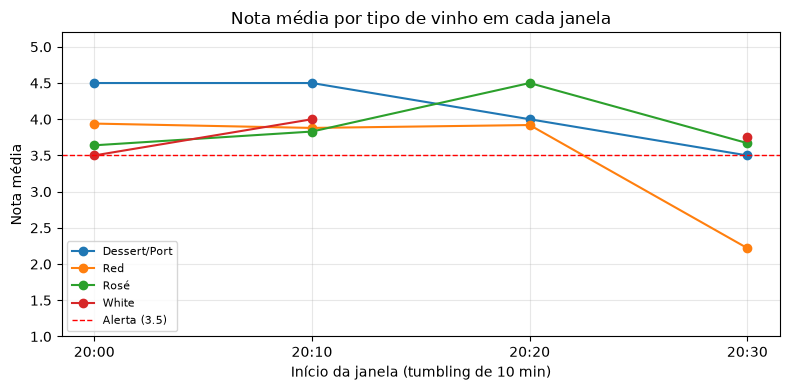

In [6]:
# Volume por janela após cada lote (soma de todos os tipos)
evolucao = (pd.concat(historico)
              .assign(janela=lambda d: d["inicio"] + "–" + d["fim"])
              .groupby(["lote", "janela"])["qtd_avaliacoes"].sum()
              .unstack("janela").fillna(0).astype(int))
evolucao.index = [f"após lote {i}" for i in evolucao.index]
print("Total de avaliações por janela, após cada lote:")
display(evolucao)

final = historico[-1]
pivo = final.pivot(index="inicio", columns="tipo", values="nota_media")
print("Nota média final por janela (linhas) e tipo de vinho (colunas):")
display(pivo)

fig, ax = plt.subplots(figsize=(8, 4))
for tipo in pivo.columns:
    ax.plot(pivo.index, pivo[tipo], marker="o", label=tipo)
ax.axhline(LIMITE_ALERTA, color="red", linestyle="--", linewidth=1, label=f"Alerta ({LIMITE_ALERTA})")
ax.set_xlabel("Início da janela (tumbling de 10 min)")
ax.set_ylabel("Nota média")
ax.set_ylim(1, 5.2)
ax.set_title("Nota média por tipo de vinho em cada janela")
ax.legend(loc="lower left", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.8 Resultados e interpretação

**Funcionamento do streaming.** Os 63 registros chegaram em 4 arquivos e foram processados em micro-lotes. O total recebido pelo Spark cresceu de forma incremental (15 → 30 → 48 → 63): cada arquivo novo foi detectado e só ele foi lido, enquanto o estado das agregações anteriores ficou guardado no *checkpoint*.

**Comportamento das janelas com a chegada de novos dados.**
- **Lotes 1 e 2** abriram as janelas 20:00–20:10 e 20:10–20:20, com 15 avaliações cada.
- **Lote 3** abriu a janela 20:20–20:30 e também **atualizou uma janela antiga**: a janela 20:00–20:10 passou de 15 para 18 avaliações. Os 3 registros atrasados (2 Rosé e 1 Dessert/Port, feitos às 20:0x) foram somados à janela do momento em que a avaliação ocorreu, e não à do momento em que chegaram. A nota média dos Rosé nessa janela passou de 3,50 para 3,64, e o tipo Dessert/Port apareceu nela. Isso mostra a diferença entre *tempo do evento* e *tempo de chegada* e por que a janela foi definida sobre `event_time`.
- **Lote 4** abriu a janela 20:30–20:40, onde os **tintos (Red) caíram para nota média 2,22** (9 avaliações, notas entre 1,5 e 2,5), contra cerca de 3,9 nas três janelas anteriores. Essa foi a única combinação janela/tipo marcada com alerta.

**Interpretação para o problema analítico.** Nas janelas "normais", as médias ficaram entre 3,5 e 4,5, coerentes com a média histórica de 3,88 calculada na RA1. A queda no último intervalo é **específica dos tintos**: Rosé (3,67), White (3,75) e Dessert/Port (3,50) se mantiveram estáveis. Ou seja, não é uma queda geral da plataforma, e sim um sinal que mereceria investigação (por exemplo, uma safra com problema). Esse tipo de leitura não aparece na média histórica estática e é exatamente o que a agregação por janela torna visível.

**Limitações.** Os dados são simulados e há poucas avaliações por janela. Alguns grupos têm só 1 registro (ex.: White às 20:00 e às 20:10), então a média desses grupos é instável e não deve ser usada sozinha para alertas; um critério melhor exigiria um volume mínimo por janela. Como não há *watermark*, o estado cresce indefinidamente. Num fluxo contínuo de produção seria necessário `withWatermark` (por exemplo, 15 minutos) e um *sink* persistente no lugar da memória.

## 2.9 Encerramento

A consulta de streaming e a sessão Spark são encerradas para liberar memória e o processo Java.

In [7]:
query.stop()
spark.stop()
print("Consulta de streaming e sessão Spark encerradas.")

Consulta de streaming e sessão Spark encerradas.


# RA3 — Análise estatística, visualização e Machine Learning

O RA3 usa a **base completa** de avaliações do X-Wines (21 milhões de registros) para responder às perguntas analíticas da equipe e testar uma aplicação de aprendizagem supervisionada.

| # | Pergunta analítica | Como respondemos |
|---|---|---|
| **P1** | Quais são os vinhos mais populares da plataforma? | Agrupamento por `WineID` e contagem de avaliações (`Total_Avaliacoes`) e concentração do volume. |
| **P2** | Qual é a qualidade percebida (nota média) de cada vinho? | Média das notas por vinho (`Nota_Media`), complementada por uma **média ponderada bayesiana**, para não premiar vinhos com poucas avaliações. |
| **P3** | Existe correlação entre o volume de avaliações e a nota média? | Correlações de Pearson e Spearman e comparação das notas por faixa de popularidade. |
| **P4** | Como se comportam as avaliações ao longo do tempo? | Série mensal e anual de volume e nota média, a partir da coluna `Date` (data e hora da avaliação), e padrão sazonal por mês do ano. |
| **ML** | É possível prever se um vinho será bem avaliado? | Classificação supervisionada (Random Forest) com atributos do vinho e sua popularidade. |

**Como executar.** A etapa 3.1 usa o Spark para agregar os 21 milhões de avaliações e salva tabelas resumidas em `dados_ra3/`, que são versionadas no repositório. Ela só roda se os CSVs brutos estiverem na pasta do projeto. Todas as etapas seguintes (3.2 a 3.9) leem apenas `dados_ra3/`, então podem ser reproduzidas por qualquer pessoa que clonar o repositório, sem os arquivos de 21 milhões de linhas. **Reinicie o kernel antes de executar o RA3.**

## 3.1 Agregação da base completa com Spark

Decisões:
- O Spark lê o CSV de avaliações com **esquema explícito** (evita a inferência de tipos sobre 21 milhões de linhas e o problema de tipos mistos em `Vintage` visto no RA1).
- A coluna `Date` é convertida para *timestamp*. Linhas com data inválida são contadas e informadas.
- O DataFrame é mantido em cache (`persist`), porque é reutilizado em cinco agregações: resumo geral, frequência das notas, agregação **por vinho**, série **mensal** e atividade **por usuário**.
- Só os resultados agregados (no máximo cerca de 100 mil linhas, uma por vinho) são trazidos para o Pandas. A junção com o cadastro de vinhos é feita no Pandas, sobre essa tabela pequena.
- Os resultados são gravados com o Pandas, e não pelo Spark, para evitar os problemas de escrita do Hadoop no Windows.

In [1]:
import os, sys, ast, glob, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

PASTA_PROJETO = Path.cwd()
ARQ_RATINGS   = PASTA_PROJETO / "XWines_Full_21M_ratings.csv"
ARQ_WINES     = PASTA_PROJETO / "XWines_Full_100K_wines.csv"
PASTA_RA3     = PASTA_PROJETO / "dados_ra3"
PASTA_RA3.mkdir(exist_ok=True)

ARQUIVOS_RA3 = {nome: PASTA_RA3 / f"{nome}.csv" for nome in
                ["resumo_geral", "frequencia_notas", "vinhos_agregados", "serie_mensal", "resumo_usuarios"]}

FORCAR_REPROCESSAMENTO = False   # True = refaz a agregação mesmo que dados_ra3/ já exista
agregados_prontos = all(p.exists() for p in ARQUIVOS_RA3.values())
brutos_disponiveis = ARQ_RATINGS.exists() and ARQ_WINES.exists()
EXECUTAR_SPARK = brutos_disponiveis and (FORCAR_REPROCESSAMENTO or not agregados_prontos)

if EXECUTAR_SPARK:
    print("CSVs brutos encontrados: a agregação com Spark será executada.")
elif agregados_prontos:
    print("Usando as tabelas já agregadas em dados_ra3/ (a etapa Spark será pulada).")
else:
    raise FileNotFoundError("Coloque XWines_Full_21M_ratings.csv e XWines_Full_100K_wines.csv na pasta do projeto "
                            "ou obtenha a pasta dados_ra3/ do repositório.")

Usando as tabelas já agregadas em dados_ra3/ (a etapa Spark será pulada).


In [2]:
if EXECUTAR_SPARK:
    # --- Java/Hadoop no Windows (mesma lógica do RA2) ---------------------------
    if os.name == "nt":
        candidatos = []
        for raiz in [r"C:\Program Files", r"C:\Program Files (x86)", os.path.expanduser(r"~\.jdks")]:
            for versao in ("17", "11"):
                candidatos += sorted(glob.glob(os.path.join(raiz, "*", f"jdk-{versao}*")) +
                                     glob.glob(os.path.join(raiz, f"jdk-{versao}*")), reverse=True)
        candidatos = [Path(c) for c in candidatos if (Path(c) / "bin" / "java.exe").exists()]
        if not candidatos:
            raise RuntimeError("Nenhum JDK 11 ou 17 encontrado (winget install Microsoft.OpenJDK.17).")
        os.environ["JAVA_HOME"] = str(candidatos[0])
        os.environ["PATH"] = str(candidatos[0] / "bin") + ";" + os.environ["PATH"]
        if Path(r"C:\hadoop\bin\winutils.exe").exists():
            os.environ["HADOOP_HOME"] = r"C:\hadoop"
            os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]
    os.environ["PYSPARK_PYTHON"] = sys.executable
    os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

    from pyspark.sql import SparkSession, functions as F
    from pyspark.sql.types import StructType, StructField, LongType, StringType, DoubleType
    from pyspark import StorageLevel

    spark = (SparkSession.builder.appName("RA3-XWines-Agregacao").master("local[*]")
             .config("spark.driver.memory", "4g")
             .config("spark.hadoop.io.native.lib.available", "false")
             .config("spark.sql.shuffle.partitions", "16")
             .config("spark.sql.session.timeZone", "UTC")
             .config("spark.ui.showConsoleProgress", "false")
             .getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")

    schema_ratings = StructType([
        StructField("RatingID", LongType()), StructField("UserID", LongType()),
        StructField("WineID", LongType()),   StructField("Vintage", StringType()),
        StructField("Rating", DoubleType()), StructField("Date", StringType()),
    ])
    ratings = (spark.read.option("header", True).schema(schema_ratings).csv(ARQ_RATINGS.as_uri())
               .withColumn("Data", F.to_timestamp("Date"))
               .select("UserID", "WineID", "Rating", "Data"))
    ratings.persist(StorageLevel.MEMORY_AND_DISK)

    # 1) Resumo geral das notas individuais
    resumo = ratings.agg(
        F.count("Rating").alias("total_avaliacoes"),
        F.countDistinct("WineID").alias("vinhos_avaliados"),
        F.countDistinct("UserID").alias("usuarios"),
        F.avg("Rating").alias("media"), F.stddev("Rating").alias("desvio_padrao"),
        F.min("Rating").alias("minimo"), F.max("Rating").alias("maximo"),
        F.percentile_approx("Rating", 0.25, 10000).alias("q1"),
        F.percentile_approx("Rating", 0.50, 10000).alias("mediana"),
        F.percentile_approx("Rating", 0.75, 10000).alias("q3"),
        F.skewness("Rating").alias("assimetria"),
        F.date_format(F.min("Data"), "yyyy-MM-dd").alias("primeira_data"),
        F.date_format(F.max("Data"), "yyyy-MM-dd").alias("ultima_data"),
        F.sum(F.col("Data").isNull().cast("int")).alias("datas_invalidas"),
    ).toPandas()

    # 2) Frequência de cada nota
    freq_notas = ratings.groupBy("Rating").count().orderBy("Rating").toPandas()

    # 3) Agregação por vinho (P1, P2, P3 e ML)
    por_vinho = (ratings.groupBy("WineID").agg(
                    F.count("Rating").alias("Total_Avaliacoes"),
                    F.avg("Rating").alias("Nota_Media"),
                    F.stddev("Rating").alias("Desvio_Nota"),
                    F.date_format(F.min("Data"), "yyyy-MM-dd").alias("Primeira_Avaliacao"),
                    F.date_format(F.max("Data"), "yyyy-MM-dd").alias("Ultima_Avaliacao"))
                 .orderBy(F.desc("Total_Avaliacoes"))
                 .toPandas())

    # 4) Série mensal (P4)
    mensal = (ratings.where(F.col("Data").isNotNull())
              .groupBy(F.date_format(F.date_trunc("month", "Data"), "yyyy-MM").alias("Mes"))
              .agg(F.count("Rating").alias("Avaliacoes"), F.avg("Rating").alias("Nota_Media"),
                   F.countDistinct("UserID").alias("Usuarios_Ativos"))
              .orderBy("Mes").toPandas())

    # 5) Atividade por usuário (representatividade)
    por_usuario = ratings.groupBy("UserID").agg(F.count("*").alias("n"))
    resumo_usuarios = por_usuario.agg(
        F.count("*").alias("usuarios"), F.avg("n").alias("media_aval_por_usuario"),
        F.percentile_approx("n", 0.5).alias("mediana_aval_por_usuario"),
        F.percentile_approx("n", 0.9).alias("p90_aval_por_usuario"),
        F.percentile_approx("n", 0.99).alias("p99_aval_por_usuario"),
        F.max("n").alias("max_aval_por_usuario"),
        F.sum(F.when(F.col("n") == 1, 1).otherwise(0)).alias("usuarios_com_1_avaliacao"),
    ).toPandas()

    ratings.unpersist()
    spark.stop()

    # --- Junção com o cadastro de vinhos (Pandas, ~100 mil linhas) -------------
    wines = pd.read_csv(ARQ_WINES, usecols=["WineID", "WineName", "Type", "Elaborate", "Grapes", "Harmonize",
                                             "ABV", "Body", "Acidity", "Country", "RegionName", "WineryName", "Vintages"])
    contar_lista = lambda s: len(ast.literal_eval(s)) if isinstance(s, str) and s.startswith("[") else 0
    wines["N_Uvas"] = wines["Grapes"].map(contar_lista)
    wines["N_Harmonizacoes"] = wines["Harmonize"].map(contar_lista)
    wines["N_Safras"] = wines["Vintages"].map(contar_lista)
    wines = wines.drop(columns=["Grapes", "Harmonize", "Vintages"])

    vinhos_agregados = por_vinho.merge(wines, on="WineID", how="left")

    resumo.to_csv(ARQUIVOS_RA3["resumo_geral"], index=False)
    freq_notas.to_csv(ARQUIVOS_RA3["frequencia_notas"], index=False)
    vinhos_agregados.to_csv(ARQUIVOS_RA3["vinhos_agregados"], index=False)
    mensal.to_csv(ARQUIVOS_RA3["serie_mensal"], index=False)
    resumo_usuarios.to_csv(ARQUIVOS_RA3["resumo_usuarios"], index=False)
    print("Agregação concluída e salva em dados_ra3/.")

In [3]:
# Carregamento das tabelas agregadas (ponto de partida reprodutível do RA3)
resumo           = pd.read_csv(ARQUIVOS_RA3["resumo_geral"]).iloc[0]
freq_notas       = pd.read_csv(ARQUIVOS_RA3["frequencia_notas"])
vinhos           = pd.read_csv(ARQUIVOS_RA3["vinhos_agregados"])
mensal           = pd.read_csv(ARQUIVOS_RA3["serie_mensal"], parse_dates=["Mes"])
resumo_usuarios  = pd.read_csv(ARQUIVOS_RA3["resumo_usuarios"]).iloc[0]
fmt = lambda x: f"{x:,.0f}".replace(",", ".")   # milhar no padrão brasileiro

print(f"Avaliações agregadas: {fmt(resumo.total_avaliacoes)}")
print(f"Vinhos avaliados:     {fmt(resumo.vinhos_avaliados)}")
print(f"Usuários:             {fmt(resumo.usuarios)}")
print(f"Período:              {resumo.primeira_data} a {resumo.ultima_data}  "
      f"(datas inválidas: {int(resumo.datas_invalidas)})")
print(f"Vinhos sem cadastro:  {vinhos['Type'].isna().sum()}")
display(vinhos.head())

Avaliações agregadas: 21.013.536
Vinhos avaliados:     100.646
Usuários:             1.056.079
Período:              2012-01-03 a 2021-12-31  (datas inválidas: 0)
Vinhos sem cadastro:  0


,WineID,Total_Avaliacoes,Nota_Media,Desvio_Nota,Primeira_Avaliacao,Ultima_Avaliacao,WineName,Type,Elaborate,ABV,Body,Acidity,Country,RegionName,WineryName,N_Uvas,N_Harmonizacoes,N_Safras
0,155289,27415,4.090,0.610,2012-03-31,2021-12-31,Rioja Reserva,Red,Varietal/100%,13.500,Full-bodied,High,Spain,Rioja,Marqués de Riscal,1,4,72
1,179010,23626,3.656,0.899,2012-04-22,2021-12-31,Red (Winemaker's Blend),Red,Assemblage/Bordeaux Red Blend,13.000,Full-bodied,High,United States,California,Apothic,3,4,37
2,179011,21216,4.079,0.743,2012-07-19,2021-12-31,Pinot Noir,Red,Varietal/100%,13.700,Medium-bodied,High,United States,Rutherford,Meiomi,1,4,46
3,111391,20913,4.689,0.506,2012-05-09,2021-12-31,Brut Champagne,Sparkling,Varietal/100%,12.500,Medium-bodied,High,France,Champagne,Dom Pérignon,1,4,72
4,167418,20817,4.071,0.607,2012-05-24,2021-12-31,Malbec,Red,Varietal/100%,13.500,Very full-bodied,High,Argentina,Mendoza,Catena Zapata,1,3,42


## 3.2 Estatística descritiva

Analisamos duas unidades de observação diferentes, pois cada pergunta depende de uma delas:
- **Avaliação individual** (`Rating`, 21 milhões de registros): escala discreta de 1,0 a 5,0 em passos de 0,5.
- **Vinho** (`Total_Avaliacoes` e `Nota_Media`, uma linha por vinho): variáveis contínuas e, no caso do volume, muito assimétricas.

As medidas escolhidas seguem essas características:
- **Média e mediana** (tendência central). A diferença entre as duas indica assimetria.
- **Desvio-padrão, amplitude e intervalo interquartil (IQR)** (dispersão). O IQR é mais robusto quando há valores extremos.
- **Coeficiente de variação e assimetria** (distribuição), além da tabela de frequência das notas.

In [4]:
def medidas(serie, nome):
    s = serie.dropna()
    return pd.Series({
        "n": len(s), "média": s.mean(), "mediana": s.median(), "desvio-padrão": s.std(),
        "mínimo": s.min(), "máximo": s.max(), "amplitude": s.max() - s.min(),
        "Q1": s.quantile(.25), "Q3": s.quantile(.75), "IQR": s.quantile(.75) - s.quantile(.25),
        "coef. variação (%)": 100 * s.std() / s.mean(), "assimetria": s.skew()}, name=nome)

medidas_nota_individual = pd.Series({
    "n": resumo.total_avaliacoes, "média": resumo.media, "mediana": resumo.mediana,
    "desvio-padrão": resumo.desvio_padrao, "mínimo": resumo.minimo, "máximo": resumo.maximo,
    "amplitude": resumo.maximo - resumo.minimo, "Q1": resumo.q1, "Q3": resumo.q3,
    "IQR": resumo.q3 - resumo.q1, "coef. variação (%)": 100 * resumo.desvio_padrao / resumo.media,
    "assimetria": resumo.assimetria}, name="Rating (avaliação individual)")

tabela_medidas = pd.concat([medidas_nota_individual,
                            medidas(vinhos["Nota_Media"], "Nota_Media (por vinho)"),
                            medidas(vinhos["Total_Avaliacoes"], "Total_Avaliacoes (por vinho)")], axis=1)
print("Medidas de tendência central, dispersão e distribuição")
display(tabela_medidas)

freq_notas["Percentual"] = 100 * freq_notas["count"] / freq_notas["count"].sum()
freq_notas["Percentual acumulado"] = freq_notas["Percentual"].cumsum()
print("Frequência das notas individuais")
display(freq_notas.rename(columns={"count": "Avaliações"}))
print(f"Moda das notas: {freq_notas.loc[freq_notas['count'].idxmax(), 'Rating']}")

Medidas de tendência central, dispersão e distribuição


,Rating (avaliação individual),Nota_Media (por vinho),Total_Avaliacoes (por vinho)
n,"21,013,536.000","100,646.000","100,646.000"
média,3.885,3.777,208.787
mediana,4.000,3.786,58.000
desvio-padrão,0.738,0.390,588.611
mínimo,1.000,1.250,5.000
máximo,5.000,5.000,"27,415.000"
amplitude,4.000,3.750,"27,410.000"
Q1,3.500,3.540,22.000
Q3,4.500,4.034,187.000
IQR,1.000,0.494,165.000


Frequência das notas individuais


,Rating,Avaliações,Percentual,Percentual acumulado
0,1.000,152452,0.725,0.725
1,1.500,64481,0.307,1.032
2,2.000,425593,2.025,3.058
3,2.500,468045,2.227,5.285
4,3.000,2755661,13.114,18.399
5,3.500,3389567,16.130,34.529
6,4.000,8301655,39.506,74.035
7,4.500,2505818,11.925,85.960
8,5.000,2950264,14.040,100.000


Moda das notas: 4.0


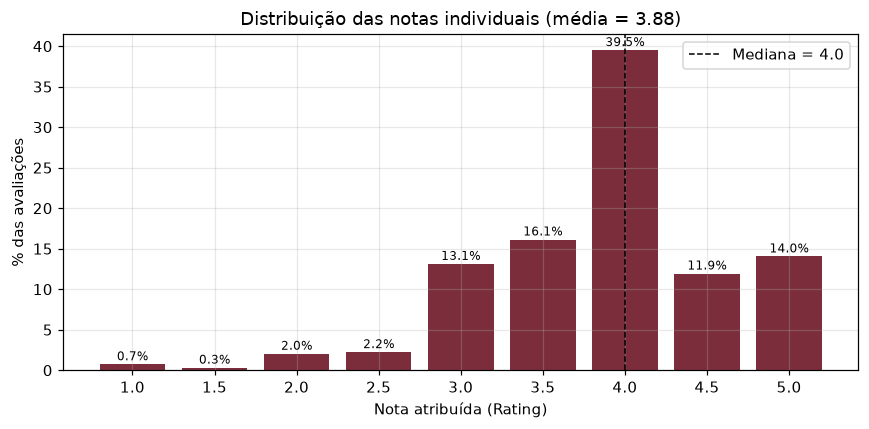

In [5]:
# Visualização 1 — Distribuição das notas individuais
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(freq_notas["Rating"].astype(str), freq_notas["Percentual"], color="#7b2d3b")
for x, p in zip(freq_notas["Rating"].astype(str), freq_notas["Percentual"]):
    ax.text(x, p + 0.5, f"{p:.1f}%", ha="center", fontsize=8)
ax.axvline(x=list(freq_notas["Rating"]).index(resumo.mediana) if resumo.mediana in list(freq_notas["Rating"]) else 0,
           color="black", ls="--", lw=1, label=f"Mediana = {resumo.mediana}")
ax.set_title(f"Distribuição das notas individuais (média = {resumo.media:.2f})")
ax.set_xlabel("Nota atribuída (Rating)")
ax.set_ylabel("% das avaliações")
ax.legend()
plt.tight_layout(); plt.show()

> ✍️ **[INTERPRETAÇÃO PENDENTE — será escrita com os números da execução completa]**

## 3.3 P1 — Quais são os vinhos mais populares?

A popularidade é medida pelo **total de avaliações recebidas** (`Total_Avaliacoes`). Além do ranking, medimos a **concentração** do volume, ou seja, que fração das avaliações fica com os vinhos mais avaliados, usando a curva de concentração (Lorenz) e o índice de Gini (0 = volume igual entre vinhos; 1 = tudo concentrado num único vinho).

In [6]:
colunas_rank = ["WineID", "WineName", "WineryName", "Type", "Country", "Total_Avaliacoes", "Nota_Media"]
top15 = vinhos.nlargest(15, "Total_Avaliacoes")[colunas_rank].reset_index(drop=True)
top15.index += 1
print("Top 15 vinhos mais avaliados")
display(top15)

# Concentração do volume de avaliações
contagens = np.sort(vinhos["Total_Avaliacoes"].to_numpy())[::-1]
participacao_acum = contagens.cumsum() / contagens.sum()
n = len(contagens)
participacao = {p: participacao_acum[max(int(n * p / 100) - 1, 0)] * 100 for p in (1, 5, 10, 20, 50)}
asc = np.sort(contagens)
gini = (2 * np.arange(1, n + 1) - n - 1).dot(asc) / (n * asc.sum())

print(f"Índice de Gini do volume de avaliações: {gini:.3f}")
for p, v in participacao.items():
    print(f"  Os {p:>2}% vinhos mais avaliados concentram {v:5.1f}% de todas as avaliações")

Top 15 vinhos mais avaliados


,WineID,WineName,WineryName,Type,Country,Total_Avaliacoes,Nota_Media
1,155289,Rioja Reserva,Marqués de Riscal,Red,Spain,27415,4.090
2,179010,Red (Winemaker's Blend),Apothic,Red,United States,23626,3.656
3,179011,Pinot Noir,Meiomi,Red,United States,21216,4.079
4,111391,Brut Champagne,Dom Pérignon,Sparkling,France,20913,4.689
5,167418,Malbec,Catena Zapata,Red,Argentina,20817,4.071
6,162494,Cabernet Sauvignon (Reserva),Casillero del Diablo,Red,Chile,20456,3.570
7,167419,Malbec,Alamos,Red,Argentina,18823,3.704
8,135825,Tignanello,Antinori,Red,Italy,18748,4.604
9,179012,Cabernet Sauvignon,Caymus,Red,United States,18575,4.600
10,167420,Malbec,Luigi Bosca,Red,Argentina,17759,4.089


Índice de Gini do volume de avaliações: 0.727
  Os  1% vinhos mais avaliados concentram  21.8% de todas as avaliações
  Os  5% vinhos mais avaliados concentram  46.5% de todas as avaliações
  Os 10% vinhos mais avaliados concentram  60.6% de todas as avaliações
  Os 20% vinhos mais avaliados concentram  76.0% de todas as avaliações
  Os 50% vinhos mais avaliados concentram  93.9% de todas as avaliações


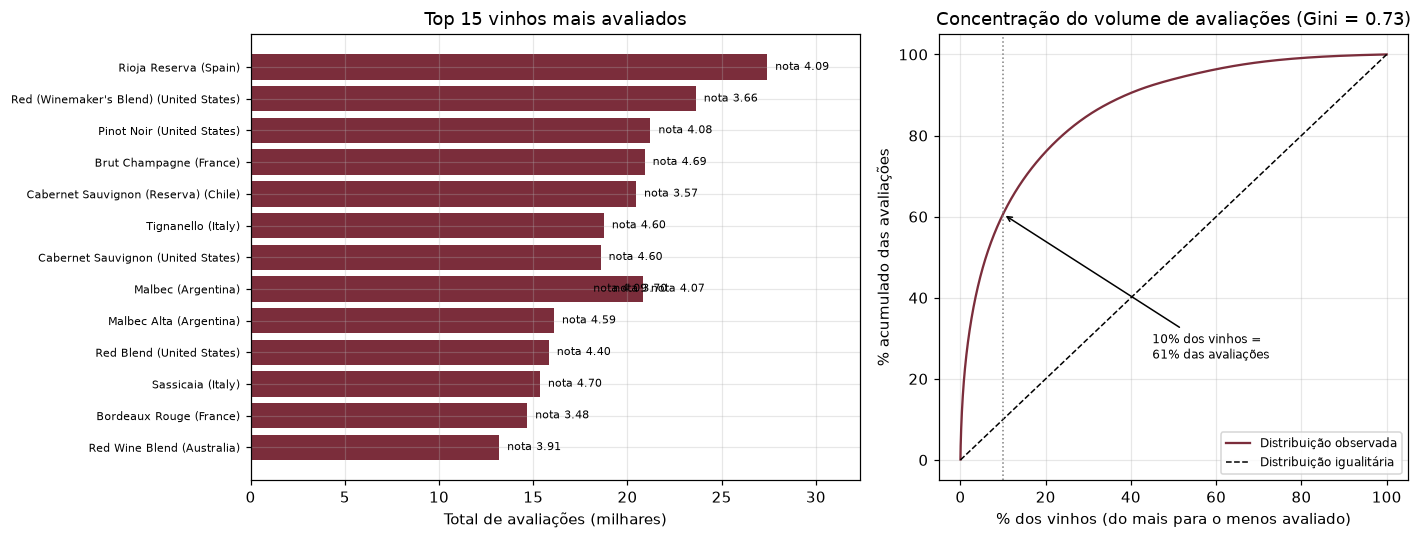

In [7]:
# Visualização 2 — Ranking dos mais avaliados e curva de concentração
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})

rotulos = [f"{r.WineName[:28]} ({r.Country})" for r in top15.itertuples()][::-1]
barras = ax1.barh(rotulos, top15["Total_Avaliacoes"][::-1] / 1000, color="#7b2d3b")
for b, nota in zip(barras, top15["Nota_Media"][::-1]):
    ax1.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  nota {nota:.2f}", va="center", fontsize=7)
ax1.set_xlim(0, top15["Total_Avaliacoes"].max() / 1000 * 1.18)
ax1.set_xlabel("Total de avaliações (milhares)")
ax1.set_title("Top 15 vinhos mais avaliados")
ax1.tick_params(axis="y", labelsize=7)

x = np.arange(1, n + 1) / n * 100
ax2.plot(x, participacao_acum * 100, color="#7b2d3b", label="Distribuição observada")
ax2.plot([0, 100], [0, 100], "k--", lw=1, label="Distribuição igualitária")
ax2.axvline(10, color="gray", ls=":", lw=1)
ax2.annotate(f"10% dos vinhos =\n{participacao[10]:.0f}% das avaliações", xy=(10, participacao[10]),
             xytext=(45, 25), arrowprops=dict(arrowstyle="->"), fontsize=8)
ax2.set_xlabel("% dos vinhos (do mais para o menos avaliado)")
ax2.set_ylabel("% acumulado das avaliações")
ax2.set_title(f"Concentração do volume de avaliações (Gini = {gini:.2f})")
ax2.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

> ✍️ **[INTERPRETAÇÃO PENDENTE — será escrita com os números da execução completa]**

## 3.4 P2 — Qual é a qualidade percebida de cada vinho?

A nota média simples (`Nota_Media`) tem um problema: um vinho com 2 avaliações nota 5,0 aparece acima de um vinho com 50 mil avaliações e média 4,6. Por isso, o ranking de qualidade usa a **média ponderada bayesiana** (a mesma ideia do ranking do IMDb):

$$\text{Nota\_Ponderada} = \frac{v}{v+m}\,R + \frac{m}{v+m}\,C$$

em que $R$ é a nota média do vinho, $v$ o número de avaliações, $C$ a média geral da plataforma e $m$ um "peso de confiança". Adotamos $m$ igual ao **3º quartil** do número de avaliações por vinho. Assim, vinhos com poucas avaliações são puxados para a média geral, e só vinhos com volume consistente se destacam.

In [8]:
C = resumo.media
m = vinhos["Total_Avaliacoes"].quantile(0.75)
v, R = vinhos["Total_Avaliacoes"], vinhos["Nota_Media"]
vinhos["Nota_Ponderada"] = (v / (v + m)) * R + (m / (v + m)) * C
print(f"Média geral C = {C:.3f} | peso de confiança m = {m:.0f} avaliações (3º quartil)")

colunas_q = ["WineName", "WineryName", "Type", "Country", "Total_Avaliacoes", "Nota_Media", "Nota_Ponderada"]
print("\nTop 10 pela nota média SIMPLES (sem considerar o volume):")
display(vinhos.nlargest(10, ["Nota_Media", "Total_Avaliacoes"])[colunas_q].reset_index(drop=True))
print("Top 10 pela nota PONDERADA (melhor qualidade percebida com volume consistente):")
display(vinhos.nlargest(10, "Nota_Ponderada")[colunas_q].reset_index(drop=True))
print("10 piores pela nota PONDERADA:")
display(vinhos.nsmallest(10, "Nota_Ponderada")[colunas_q].reset_index(drop=True))

nota_por_tipo = (vinhos.groupby("Type")
                 .agg(Vinhos=("WineID", "count"), Mediana_Nota=("Nota_Media", "median"),
                      Media_Nota=("Nota_Media", "mean"), Desvio_Nota=("Nota_Media", "std"))
                 .sort_values("Mediana_Nota", ascending=False))
print("Nota média dos vinhos por tipo:")
display(nota_por_tipo)

Média geral C = 3.885 | peso de confiança m = 187 avaliações (3º quartil)

Top 10 pela nota média SIMPLES (sem considerar o volume):


,WineName,WineryName,Type,Country,Total_Avaliacoes,Nota_Media,Nota_Ponderada
0,Bâtard-Montrachet Grand Cru,Domaine de Chassorney,White,France,6,5.000,3.920
1,Brigante Crocco Merlot,Cantine Crocco,Red,Italy,5,5.000,3.914
2,Frattey Shams Anderson Valley Pinot Noir,Pinoli Cole,Red,United States,5,5.000,3.914
3,Jusqu'a l'Os,Sine Qua Non,Red,United States,18,4.944,3.978
4,Pajarito del Amor,Sine Qua Non,Red,United States,9,4.944,3.934
5,Vintage Porto,Constantino,Dessert/Port,Portugal,9,4.944,3.934
6,Clos d'Ambonnay Blanc de Noirs Brut Champagne,Krug,Sparkling,France,157,4.943,4.368
7,Wraith Cabernet Sauvignon,Hundred Acre,Red,United States,90,4.939,4.227
8,Saint Nicholas,Dolce,Dessert,United States,7,4.929,3.923
9,Treehouse Pinot Noir,Cirq,Red,United States,155,4.923,4.355


Top 10 pela nota PONDERADA (melhor qualidade percebida com volume consistente):


,WineName,WineryName,Type,Country,Total_Avaliacoes,Nota_Media,Nota_Ponderada
0,Sauternes,Château d'Yquem,Dessert,France,6475,4.808,4.782
1,Unico,Vega Sicilia,Red,Spain,6774,4.807,4.782
2,Pêra-Manca Tinto,Cartuxa,Red,Portugal,4675,4.784,4.749
3,Barca Velha Douro,Casa Ferreirinha,Red,Portugal,2710,4.807,4.747
4,Toscana,Masseto,Red,Italy,2187,4.813,4.740
5,Pomerol,Pétrus,Red,France,4369,4.774,4.737
6,Unico Reserva Especial Edición,Vega Sicilia,Red,Spain,1896,4.808,4.725
7,Grange,Penfolds,Red,Australia,4003,4.761,4.722
8,Gran Enemigo Single Vineyard Gualtallary Caber...,El Enemigo,Red,Argentina,7063,4.738,4.716
9,Amarone della Valpolicella Classico,Quintarelli Giuseppe,Red,Italy,1394,4.825,4.714


10 piores pela nota PONDERADA:


,WineName,WineryName,Type,Country,Total_Avaliacoes,Nota_Media,Nota_Ponderada
0,Seco Tinto,Quinta do Morgado,Red,Brazil,223,2.099,2.913
1,Classic Reserva Especial Cabernet Sauvignon,Salton,Red,Brazil,948,2.745,2.933
2,Tinto Suave,Chalise,Red,Brazil,374,2.457,2.933
3,Tinto,Don Valentin Lacrado,Red,Argentina,778,2.726,2.951
4,Tinto,Cruzares,Red,Spain,320,2.425,2.963
5,Cabernet Sauvignon,Almadén,Red,Brazil,712,2.735,2.974
6,Tinto,Soldepeñas,Red,Spain,352,2.562,3.021
7,Sélección Vino Tinto,Bodegas Santa Ana,Red,Argentina,370,2.593,3.027
8,Seleccion Tempranillo,Don Simón,Red,Spain,3689,2.984,3.027
9,Classic Reserva Especial Merlot,Salton,Red,Brazil,742,2.850,3.059


Nota média dos vinhos por tipo:


,Vinhos,Mediana_Nota,Media_Nota,Desvio_Nota
Type,,,,
Dessert,2409,4.013,3.988,0.369
Dessert/Port,1112,4.000,4.002,0.365
Red,56162,3.801,3.796,0.402
White,29196,3.763,3.749,0.365
Sparkling,7366,3.753,3.741,0.364
Rosé,4401,3.633,3.605,0.347


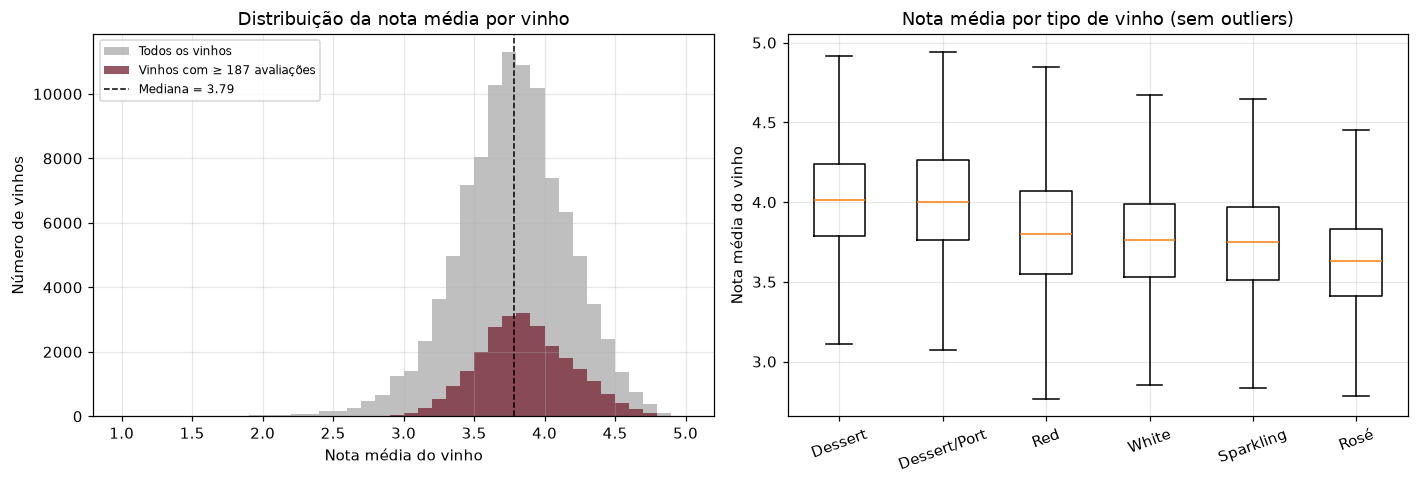

In [9]:
# Visualização 3 — Distribuição da nota média por vinho e por tipo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.arange(1, 5.01, 0.1)
ax1.hist(vinhos["Nota_Media"], bins=bins, alpha=0.5, color="gray", label="Todos os vinhos")
ax1.hist(vinhos.loc[vinhos["Total_Avaliacoes"] >= m, "Nota_Media"], bins=bins, alpha=0.8,
         color="#7b2d3b", label=f"Vinhos com ≥ {m:.0f} avaliações")
ax1.axvline(vinhos["Nota_Media"].median(), color="black", ls="--", lw=1,
            label=f"Mediana = {vinhos['Nota_Media'].median():.2f}")
ax1.set_xlabel("Nota média do vinho")
ax1.set_ylabel("Número de vinhos")
ax1.set_title("Distribuição da nota média por vinho")
ax1.legend(fontsize=8)

ordem = nota_por_tipo.index.tolist()
ax2.boxplot([vinhos.loc[vinhos["Type"] == t, "Nota_Media"] for t in ordem], showfliers=False)
ax2.set_xticks(range(1, len(ordem) + 1), ordem, rotation=20)
ax2.set_ylabel("Nota média do vinho")
ax2.set_title("Nota média por tipo de vinho (sem outliers)")
plt.tight_layout(); plt.show()

> ✍️ **[INTERPRETAÇÃO PENDENTE — será escrita com os números da execução completa]**

## 3.5 P3 — Existe correlação entre o volume de avaliações e a nota média?

Calculamos duas correlações:
- **Pearson**, sobre o logaritmo do volume, porque o volume é muito assimétrico e o log aproxima a relação de uma reta.
- **Spearman**, sobre os *postos* (rankings). É robusta a outliers e não exige relação linear.

Também comparamos os vinhos por **faixas de popularidade**. Se as notas inflacionadas vêm de poucas avaliações, a **dispersão** das médias deve ser muito maior nas faixas de baixo volume.

In [10]:
vinhos["Log10_Avaliacoes"] = np.log10(vinhos["Total_Avaliacoes"])
pearson = vinhos["Log10_Avaliacoes"].corr(vinhos["Nota_Media"], method="pearson")
spearman = vinhos["Total_Avaliacoes"].corr(vinhos["Nota_Media"], method="spearman")
print(f"Correlação de Pearson  (log10 volume x nota média): {pearson:+.3f}")
print(f"Correlação de Spearman (volume x nota média):        {spearman:+.3f}")

limites = [0, 9, 49, 199, 999, 9999, np.inf]
nomes = ["1–9", "10–49", "50–199", "200–999", "1.000–9.999", "10.000+"]
vinhos["Faixa_Popularidade"] = pd.cut(vinhos["Total_Avaliacoes"], bins=limites, labels=nomes)
por_faixa = (vinhos.groupby("Faixa_Popularidade", observed=True)
             .agg(Vinhos=("WineID", "count"),
                  Nota_Media=("Nota_Media", "mean"),
                  Mediana=("Nota_Media", "median"),
                  Desvio=("Nota_Media", "std"),
                  Pct_Media_4_5_ou_mais=("Nota_Media", lambda s: 100 * (s >= 4.5).mean()),
                  Pct_Media_abaixo_3=("Nota_Media", lambda s: 100 * (s < 3).mean())))
print("\nNota média por faixa de popularidade (nº de avaliações do vinho):")
display(por_faixa)

Correlação de Pearson  (log10 volume x nota média): +0.178
Correlação de Spearman (volume x nota média):        +0.158

Nota média por faixa de popularidade (nº de avaliações do vinho):


,Vinhos,Nota_Media,Mediana,Desvio,Pct_Media_4_5_ou_mais,Pct_Media_abaixo_3
Faixa_Popularidade,,,,,,
1–9,11456,3.664,3.700,0.499,4.365,8.371
10–49,32857,3.714,3.727,0.399,2.264,4.121
50–199,32595,3.821,3.815,0.357,3.025,1.218
200–999,19980,3.847,3.833,0.327,2.723,0.410
1.000–9.999,3711,3.918,3.890,0.324,4.716,0.027
10.000+,47,4.137,4.089,0.345,19.149,0.000


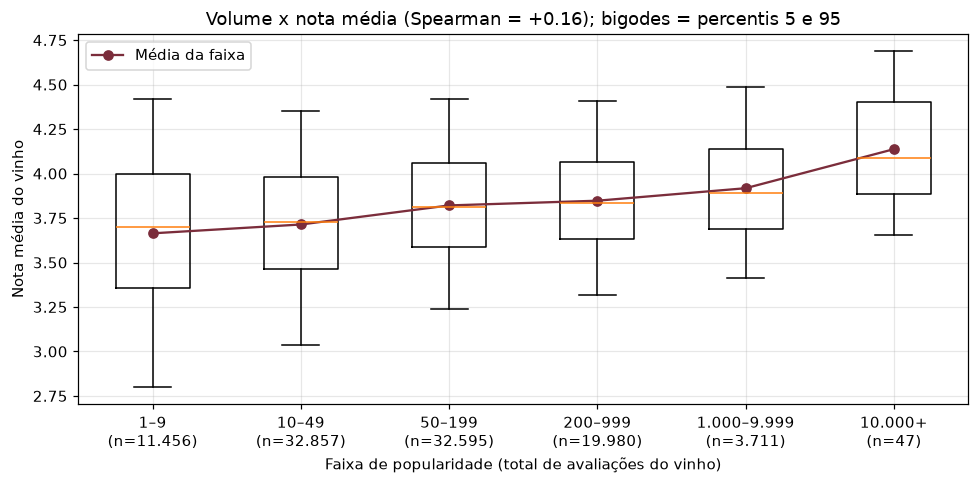

In [11]:
# Visualização 4 — Nota média por faixa de popularidade
fig, ax = plt.subplots(figsize=(9, 4.5))
dados_box = [vinhos.loc[vinhos["Faixa_Popularidade"] == f, "Nota_Media"] for f in por_faixa.index]
ax.boxplot(dados_box, whis=(5, 95), showfliers=False)
ax.plot(range(1, len(por_faixa) + 1), por_faixa["Nota_Media"], "o-", color="#7b2d3b", label="Média da faixa")
ax.set_xticks(range(1, len(por_faixa) + 1),
              [f"{f}\n(n={fmt(q)})" for f, q in zip(por_faixa.index, por_faixa["Vinhos"])])
ax.set_xlabel("Faixa de popularidade (total de avaliações do vinho)")
ax.set_ylabel("Nota média do vinho")
ax.set_title(f"Volume x nota média (Spearman = {spearman:+.2f}); bigodes = percentis 5 e 95")
ax.legend()
plt.tight_layout(); plt.show()

> ✍️ **[INTERPRETAÇÃO PENDENTE — será escrita com os números da execução completa]**

## 3.6 P4 — Como se comportam as avaliações ao longo do tempo?

A série é construída sobre a coluna `Date` (data e hora em que a avaliação foi registrada), agregada por mês no Spark. Analisamos:
- a **evolução anual** do volume, da nota média e dos usuários ativos;
- a **série mensal**, para identificar picos;
- a **sazonalidade**: a participação média de cada mês do ano no volume anual, calculada só com os anos completos.

In [12]:
mensal["Ano"] = mensal["Mes"].dt.year
mensal["Mes_do_Ano"] = mensal["Mes"].dt.month

anual = (mensal.groupby("Ano")
         .apply(lambda g: pd.Series({
             "Avaliacoes": g["Avaliacoes"].sum(),
             "Nota_Media": np.average(g["Nota_Media"], weights=g["Avaliacoes"]),
             "Meses_com_dados": g["Mes"].nunique()}), include_groups=False))
anual["Crescimento_%"] = anual["Avaliacoes"].pct_change() * 100
print("Evolução anual:")
display(anual)

anos_completos = anual.index[anual["Meses_com_dados"] == 12]
base_sazonal = mensal[mensal["Ano"].isin(anos_completos)].copy()
base_sazonal["Pct_do_Ano"] = 100 * base_sazonal["Avaliacoes"] / base_sazonal.groupby("Ano")["Avaliacoes"].transform("sum")
sazonal = base_sazonal.groupby("Mes_do_Ano").agg(Pct_Medio_do_Ano=("Pct_do_Ano", "mean"),
                                                 Nota_Media=("Nota_Media", "mean"))
print(f"Sazonalidade (anos completos: {list(anos_completos)}):")
display(sazonal.T)

pico = mensal.loc[mensal["Avaliacoes"].idxmax()]
print(f"Mês com mais avaliações: {pico['Mes']:%m/%Y} ({fmt(pico['Avaliacoes'])} avaliações)")
print(f"Amplitude da nota média mensal (meses com ≥ 1.000 avaliações): "
      f"{mensal.loc[mensal['Avaliacoes'] >= 1000, 'Nota_Media'].agg(['min', 'max']).round(3).tolist()}")

Evolução anual:


,Avaliacoes,Nota_Media,Meses_com_dados,Crescimento_%
Ano,,,,
2012,"53,699.000",3.904,12.000,NaN
2013,"464,462.000",3.722,12.000,764.936
2014,"1,403,015.000",3.746,12.000,202.073
2015,"1,805,355.000",3.788,12.000,28.677
2016,"1,900,597.000",3.817,12.000,5.276
2017,"2,204,047.000",3.843,12.000,15.966
2018,"2,682,560.000",3.882,12.000,21.711
2019,"3,207,094.000",3.915,12.000,19.553
2020,"3,658,529.000",3.935,12.000,14.076


Sazonalidade (anos completos: [2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]):


Mes_do_Ano,1,2,3,4,5,6,7,8,9,10,11,12
Pct_Medio_do_Ano,6.865,6.129,6.809,7.194,7.746,7.424,9.427,8.281,8.254,9.174,9.816,12.882
Nota_Media,3.829,3.819,3.862,3.855,3.857,3.853,3.840,3.849,3.861,3.862,3.866,3.890


Mês com mais avaliações: 12/2020 (387.835 avaliações)
Amplitude da nota média mensal (meses com ≥ 1.000 avaliações): [3.677, 4.035]


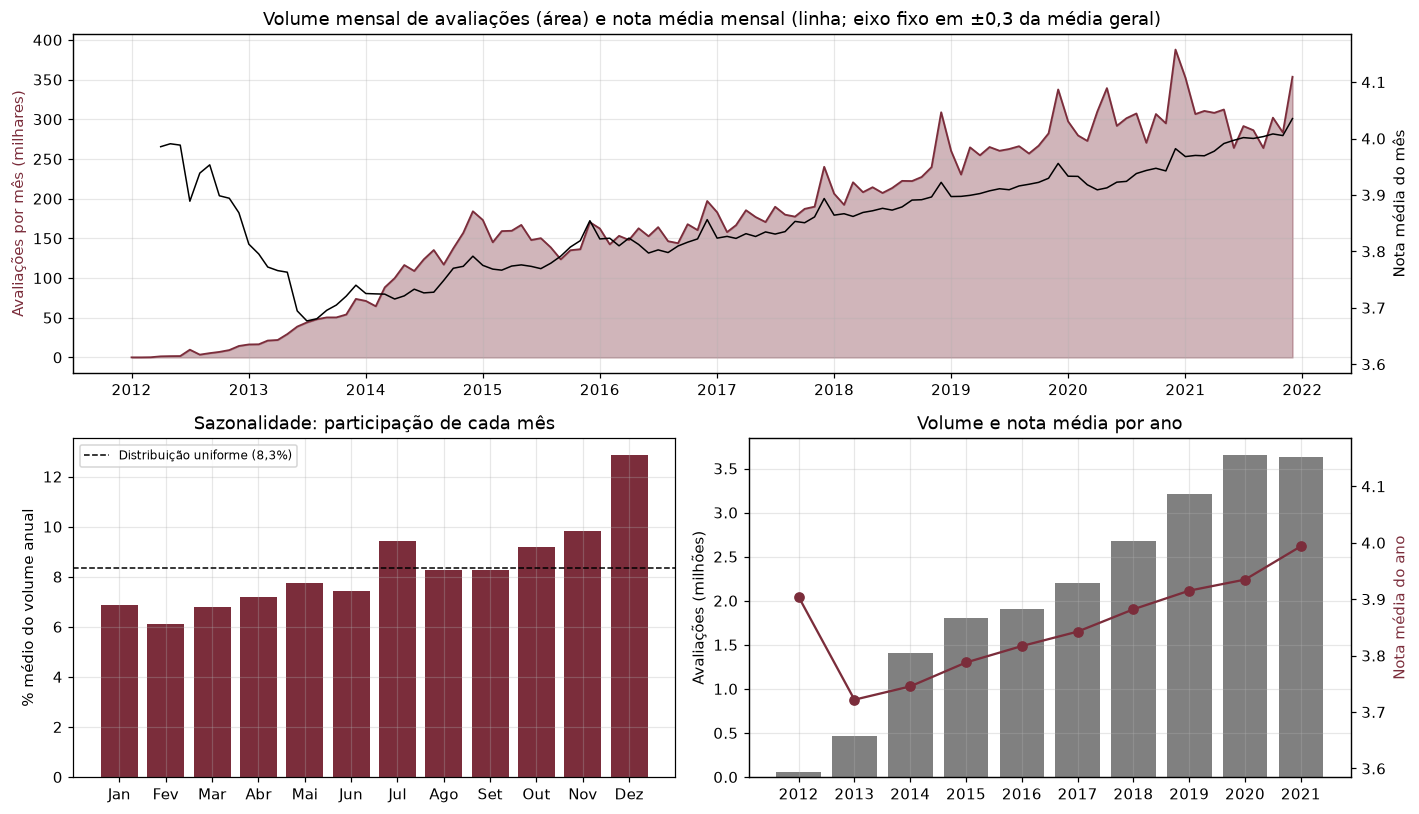

In [13]:
# Visualização 5 — Série temporal mensal e sazonalidade
fig = plt.figure(figsize=(13, 7.5))
ax1 = fig.add_subplot(2, 1, 1)
ax1.fill_between(mensal["Mes"], mensal["Avaliacoes"] / 1000, color="#7b2d3b", alpha=0.35)
ax1.plot(mensal["Mes"], mensal["Avaliacoes"] / 1000, color="#7b2d3b", lw=1.2)
ax1.set_ylabel("Avaliações por mês (milhares)", color="#7b2d3b")
ax1b = ax1.twinx()
confiavel = mensal["Avaliacoes"] >= 1000
ax1b.plot(mensal.loc[confiavel, "Mes"], mensal.loc[confiavel, "Nota_Media"], color="black", lw=1)
ax1b.set_ylim(resumo.media - 0.3, resumo.media + 0.3)
ax1b.set_ylabel("Nota média do mês")
ax1b.grid(False)
ax1.set_title("Volume mensal de avaliações (área) e nota média mensal (linha; eixo fixo em ±0,3 da média geral)")

ax2 = fig.add_subplot(2, 2, 3)
meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
ax2.bar(meses, sazonal["Pct_Medio_do_Ano"], color="#7b2d3b")
ax2.axhline(100 / 12, color="black", ls="--", lw=1, label="Distribuição uniforme (8,3%)")
ax2.set_ylabel("% médio do volume anual")
ax2.set_title("Sazonalidade: participação de cada mês")
ax2.legend(fontsize=8)

ax3 = fig.add_subplot(2, 2, 4)
ax3.bar(anual.index.astype(str), anual["Avaliacoes"] / 1e6, color="gray")
ax3.set_ylabel("Avaliações (milhões)")
ax3b = ax3.twinx()
ax3b.plot(anual.index.astype(str), anual["Nota_Media"], "o-", color="#7b2d3b")
ax3b.set_ylim(resumo.media - 0.3, resumo.media + 0.3)
ax3b.set_ylabel("Nota média do ano", color="#7b2d3b")
ax3b.grid(False)
ax3.set_title("Volume e nota média por ano")
plt.tight_layout(); plt.show()

> ✍️ **[INTERPRETAÇÃO PENDENTE — será escrita com os números da execução completa]**

## 3.7 Amostragem e representatividade

**Origem e abrangência.** O X-Wines é uma base pública para pesquisa, construída a partir de dados de uma plataforma online de avaliação de vinhos. O cadastro cobre cerca de 100 mil vinhos de dezenas de países, e as avaliações vêm de usuários reais da plataforma, registradas entre 2012 e 2021.

**Amostragem.** O RA3 **não usa amostra**: todas as avaliações são processadas com Spark. A amostra de 100 mil linhas criada no RA1 (`x_wines_preparado_amostra.csv`, sorteio aleatório simples com `random_state=42`) serviu só para versionamento. Ela não é adequada para as perguntas deste RA, porque o sorteio de avaliações individuais dilui o volume por vinho (a maioria dos vinhos aparece uma única vez na amostra), o que distorceria P1, P2 e P3. A única divisão aleatória do RA3 é a separação entre treino e teste do modelo (seção 3.8).

Os números abaixo sustentam a discussão de representatividade e vieses.

In [14]:
aval_por_pais = vinhos.groupby("Country")["Total_Avaliacoes"].sum().sort_values(ascending=False)
pct_pais = 100 * aval_por_pais / aval_por_pais.sum()
aval_por_tipo = 100 * vinhos.groupby("Type")["Total_Avaliacoes"].sum() / vinhos["Total_Avaliacoes"].sum()
pct_vinhos_tipo = 100 * vinhos["Type"].value_counts(normalize=True)

print(f"Países com vinhos avaliados: {vinhos['Country'].nunique()}")
print(f"Os 5 países com mais avaliações concentram {pct_pais.head(5).sum():.1f}% do volume: "
      + ", ".join(f"{p} ({v:.1f}%)" for p, v in pct_pais.head(5).items()))
print(f"Países fora do top 10 somados: {pct_pais.iloc[10:].sum():.1f}% das avaliações")
print("\nParticipação por tipo de vinho:")
display(pd.DataFrame({"% dos vinhos": pct_vinhos_tipo, "% das avaliações": aval_por_tipo})
        .sort_values("% das avaliações", ascending=False))

u = resumo_usuarios
print("Atividade dos usuários:")
print(f"  {fmt(u.usuarios)} usuários | média de {u.media_aval_por_usuario:.1f} avaliações por usuário; "
      f"mediana de {fmt(u.mediana_aval_por_usuario)}")
print(f"  10% dos usuários fizeram {fmt(u.p90_aval_por_usuario)} ou mais avaliações; "
      f"1% fez {fmt(u.p99_aval_por_usuario)} ou mais; o máximo foi {fmt(u.max_aval_por_usuario)}")
print(f"  {100 * u.usuarios_com_1_avaliacao / u.usuarios:.1f}% dos usuários fizeram só 1 avaliação")
print(f"\nNotas ≥ 4,0 representam {freq_notas.loc[freq_notas['Rating'] >= 4, 'Percentual'].sum():.1f}% das avaliações; "
      f"notas ≤ 2,5 representam {freq_notas.loc[freq_notas['Rating'] <= 2.5, 'Percentual'].sum():.1f}%.")

Países com vinhos avaliados: 62
Os 5 países com mais avaliações concentram 71.7% do volume: Italy (20.1%), France (19.1%), United States (13.2%), Spain (11.0%), Argentina (8.3%)
Países fora do top 10 somados: 6.6% das avaliações

Participação por tipo de vinho:


,% dos vinhos,% das avaliações
Type,,
Red,55.802,73.245
White,29.009,18.257
Sparkling,7.319,4.610
Rosé,4.373,2.249
Dessert,2.394,0.968
Dessert/Port,1.105,0.671


Atividade dos usuários:
  1.056.079 usuários | média de 19.9 avaliações por usuário; mediana de 11
  10% dos usuários fizeram 34 ou mais avaliações; 1% fez 163 ou mais; o máximo foi 2.986
  0.0% dos usuários fizeram só 1 avaliação

Notas ≥ 4,0 representam 65.5% das avaliações; notas ≤ 2,5 representam 5.3%.


> ✍️ **[INTERPRETAÇÃO PENDENTE — será escrita com os números da execução completa]**

## 3.8 Machine Learning — classificação de vinhos bem avaliados

**Problema preditivo.** A partir das características de um vinho e da sua popularidade, é possível prever se ele será **bem avaliado** pela comunidade? Isso conecta P2 (qualidade percebida) e P3 (volume x nota).

- **Tipo de problema:** classificação binária.
- **Variável-alvo (`Bem_Avaliado`):** 1 se a nota média do vinho for **≥ 4,0** (o patamar "muito bom" da escala, e a nota mais frequente na base), 0 caso contrário.
- **Filtro:** só vinhos com **pelo menos 30 avaliações**. Abaixo disso, a média é instável demais (P3) e o rótulo seria pouco confiável.
- **Features:**
  - categóricas: `Type`, `Body`, `Acidity`, `Elaborate`, `Country` (os 15 países mais frequentes; os demais viram "Outros");
  - numéricas: `ABV`, `N_Uvas`, `N_Harmonizacoes`, `N_Safras` e `Log10_Avaliacoes`.
- **Fora das features:** identificadores e nomes, que não generalizam, e qualquer estatística derivada das notas, porque isso vazaria o alvo.
- **Separação:** 80% treino e 20% teste, estratificada pelo alvo, com `random_state=42`.
- **Modelo:** Random Forest (200 árvores, `class_weight="balanced"`). É robusto, captura relações não lineares e não exige normalizar as variáveis. Como **referência mínima**, usamos um classificador que sempre prevê a classe mais frequente.
- **Métricas:**
  - acurácia;
  - **F1** da classe "bem avaliado" (equilibra precisão e revocação quando as classes são desbalanceadas);
  - **ROC-AUC** (capacidade de ordenar vinhos bons acima dos demais, independentemente do limiar);
  - matriz de confusão.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

MIN_AVALIACOES_ML = 30
LIMIAR_BEM_AVALIADO = 4.0

base_ml = vinhos[(vinhos["Total_Avaliacoes"] >= MIN_AVALIACOES_ML) & vinhos["Type"].notna()].copy()
top_paises = base_ml["Country"].value_counts().head(15).index
base_ml["Country"] = base_ml["Country"].where(base_ml["Country"].isin(top_paises), "Outros")
base_ml["Bem_Avaliado"] = (base_ml["Nota_Media"] >= LIMIAR_BEM_AVALIADO).astype(int)

FEATURES_CAT = ["Type", "Body", "Acidity", "Elaborate", "Country"]
FEATURES_NUM = ["ABV", "N_Uvas", "N_Harmonizacoes", "N_Safras", "Log10_Avaliacoes"]
base_ml[FEATURES_CAT] = base_ml[FEATURES_CAT].fillna("Desconhecido")
base_ml[FEATURES_NUM] = base_ml[FEATURES_NUM].fillna(base_ml[FEATURES_NUM].median())

X, y = base_ml[FEATURES_CAT + FEATURES_NUM], base_ml["Bem_Avaliado"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Vinhos na base do modelo (≥ {MIN_AVALIACOES_ML} avaliações): {fmt(len(base_ml))}")
print(f"Treino: {fmt(len(X_treino))} | Teste: {fmt(len(X_teste))}")
print(f"Proporção de 'bem avaliados' (nota média ≥ {LIMIAR_BEM_AVALIADO}): {100 * y.mean():.1f}%")

Vinhos na base do modelo (≥ 30 avaliações): 69.557
Treino: 55.645 | Teste: 13.912
Proporção de 'bem avaliados' (nota média ≥ 4.0): 29.6%


In [16]:
preprocessamento = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), FEATURES_CAT),
    ("num", "passthrough", FEATURES_NUM),
])
modelo = Pipeline([
    ("prep", preprocessamento),
    ("rf", RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                                  n_jobs=-1, random_state=42)),
])
modelo.fit(X_treino, y_treino)
referencia = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)

y_prev = modelo.predict(X_teste)
y_prob = modelo.predict_proba(X_teste)[:, 1]
y_ref = referencia.predict(X_teste)

metricas = pd.DataFrame({
    "Referência (classe mais frequente)": [accuracy_score(y_teste, y_ref), f1_score(y_teste, y_ref, zero_division=0), 0.5],
    "Random Forest": [accuracy_score(y_teste, y_prev), f1_score(y_teste, y_prev), roc_auc_score(y_teste, y_prob)],
}, index=["Acurácia", "F1 (classe bem avaliado)", "ROC-AUC"])
print("Desempenho no conjunto de TESTE:")
display(metricas)
print(classification_report(y_teste, y_prev, target_names=["Não (< 4,0)", "Bem avaliado (≥ 4,0)"], digits=3))

exemplos = X_teste.head(5).assign(Prob_Bem_Avaliado=y_prob[:5].round(3), Previsto=y_prev[:5], Real=y_teste.head(5).values)
print("Exemplos de previsões:")
display(exemplos)

Desempenho no conjunto de TESTE:


,Referência (classe mais frequente),Random Forest
Acurácia,0.704,0.750
F1 (classe bem avaliado),0.000,0.624
ROC-AUC,0.500,0.811


                      precision    recall  f1-score   support

         Não (< 4,0)      0.860     0.771     0.813      9796
Bem avaliado (≥ 4,0)      0.562     0.701     0.624      4116

            accuracy                          0.750     13912
           macro avg      0.711     0.736     0.719     13912
        weighted avg      0.772     0.750     0.757     13912

Exemplos de previsões:


,Type,Body,Acidity,Elaborate,Country,ABV,N_Uvas,N_Harmonizacoes,N_Safras,Log10_Avaliacoes,Prob_Bem_Avaliado,Previsto,Real
56984,Red,Full-bodied,High,Varietal/100%,United States,15.700,1,4,15,1.690,0.852,1,1
12189,Red,Full-bodied,High,Varietal/100%,Germany,13.000,1,4,20,2.577,0.323,0,0
44857,Red,Medium-bodied,High,Varietal/100%,France,14.100,1,3,22,1.851,0.543,1,0
64699,White,Full-bodied,High,Varietal/100%,France,13.000,1,4,26,1.568,0.547,1,1
39902,Sparkling,Medium-bodied,High,Assemblage/Blend,France,12.000,2,4,24,1.964,0.624,1,0


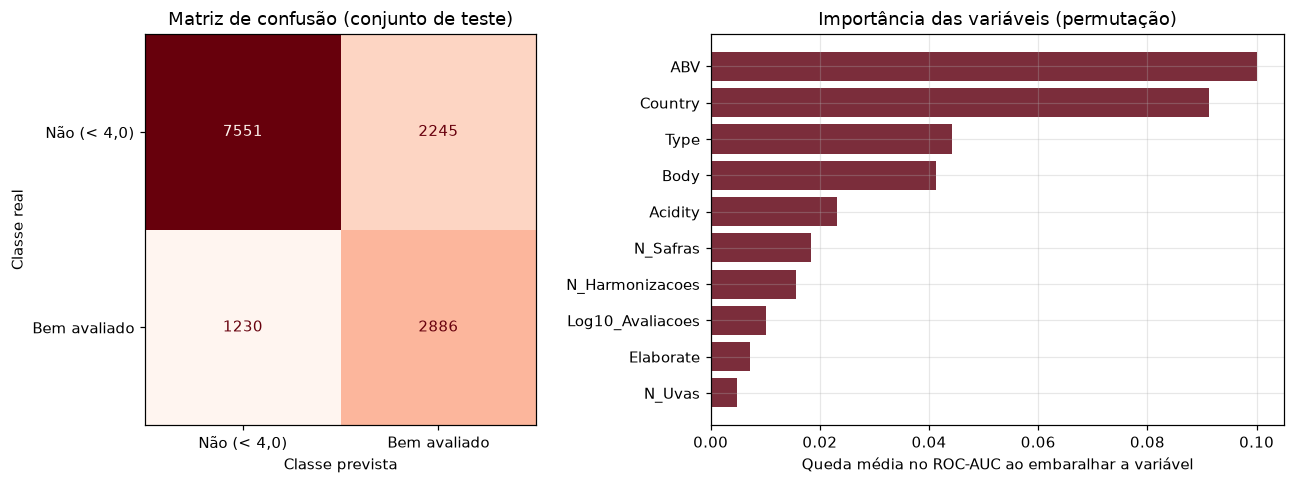

,Importância (Δ ROC-AUC)
ABV,0.100
Country,0.091
Type,0.044
Body,0.041
Acidity,0.023
N_Safras,0.018
N_Harmonizacoes,0.016
Log10_Avaliacoes,0.010
Elaborate,0.007
N_Uvas,0.005


In [17]:
# Visualização 6 — Matriz de confusão e importância das variáveis
imp = permutation_importance(modelo, X_teste, y_teste, scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=X_teste.columns).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
ConfusionMatrixDisplay(confusion_matrix(y_teste, y_prev),
                       display_labels=["Não (< 4,0)", "Bem avaliado"]).plot(ax=ax1, cmap="Reds", colorbar=False)
ax1.set_title("Matriz de confusão (conjunto de teste)")
ax1.set_xlabel("Classe prevista"); ax1.set_ylabel("Classe real"); ax1.grid(False)

ax2.barh(importancia.index, importancia.values, color="#7b2d3b")
ax2.set_xlabel("Queda média no ROC-AUC ao embaralhar a variável")
ax2.set_title("Importância das variáveis (permutação)")
plt.tight_layout(); plt.show()
display(importancia.sort_values(ascending=False).to_frame("Importância (Δ ROC-AUC)"))

> ✍️ **[INTERPRETAÇÃO PENDENTE — será escrita com os números da execução completa]**

## 3.9 Conclusões do RA3

> ✍️ **[INTERPRETAÇÃO PENDENTE — será escrita com os números da execução completa]**